# **Exploring the mental health interactions based on updated SNOWMED code list**

**Note**

1. Only 778 unique SNOWMED codes have been extracted from the exhaustive list of 5233 codes.

2. Around 1,054 individuals in the GP records don't have address history

3. There are NaN values in person_id of the GP records dataset

4. In the address history dataset, individuals may have different LSOAs for the same date. No information available on how the individuals on benefit or availing council housing are moved. May be a data quality issue.

5. **DateTo** in the LSOA address hisotry table refers to Dateuntil when the person lived in that LSOA if it is was recorded.

6. **DateEvenRecorded** comes from the Magentus and specifies the time when the event was recorded in the system. 

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
from pandas_gbq import read_gbq
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import numpy as np
from scipy.stats import zscore
import pandas as pd
import contextily as cx

In [3]:
sns.set(rc={'figure.figsize':(11, 4)})
plt.rcParams['font.family'] = 'DejaVu Sans'

font_properties = {'family': 'sans-serif','weight': 'bold','size': 12}
tickfont_properties = {'family': 'sans-serif','size': 9}

In [4]:
query = """
SELECT person_id_hashed, cb_duplicate_data, SNOMEDCode, SNOMEDText,DateEventRecorded  
FROM `yhcr-prd-bradfor-bia-core.CB_2797_PoliceMentalHealth.tbl_primarycare_21July_dedup`
"""

In [5]:
df_mh_interac = read_gbq(query, project_id="yhcr-prd-bradfor-bia-core", use_bqstorage_api=False)
df_mh_interac.head(2)

Downloading: 100%|██████████|


,person_id_hashed,cb_duplicate_data,SNOMEDCode,SNOMEDText,DateEventRecorded
0,None,None,35489007,None,2021-04-07 16:34:36+00:00
1,34A5606C1C04C9576501C737DED010E5F394EC405EF113...,None,271952001,None,2021-01-25 17:34:16+00:00


## Getting rid of the data that does not contain any person_id

In [6]:
df_mh_all_pid = df_mh_interac[~df_mh_interac['person_id_hashed'].isna()]

## **Demand Estimation**

To accurately estimate the **daily demand** from the raw dataset containing SNOMED codes, we need to account for the possibility that **multiple codes may be recorded for the same individual on the same date**. A direct group-by operation on the date field would overestimate the demand, as it would count each SNOMED entry separately, even if they belong to the same person on the same day.

To address this, we follow a two-step aggregation process:

1. **Group by Person and Date**<br>
First, we group the data by individual ID and date to ensure that each person is counted only once per day, regardless of how many SNOMED codes are associated with them on that date.

2. **Group by Date**<br>
Next, we aggregate the results by date to compute the total number of unique individuals who had any recorded activity on each day. This gives us a more accurate measure of daily service demand.

This approach ensures that the demand metric reflects **person-level activity per day**, rather than the volume of SNOMED-coded entries.

## Aggregating data based on person_id and date

In [7]:
df_mh_all_pid['DateEventRecorded'] = pd.to_datetime(df_mh_all_pid['DateEventRecorded'])
df_mh_day_agg = df_mh_all_pid.groupby(['person_id_hashed',df_mh_all_pid['DateEventRecorded'].dt.date]).size().reset_index(name='Count')

In [8]:
df_mh_day_agg = df_mh_day_agg.sort_values(by='Count', ascending=False)
df_mh_day_agg['Cumulative%'] =df_mh_day_agg['Count'].cumsum() / df_mh_day_agg['Count'].sum() * 100

In [9]:
bins= [1,2,3,4,5,10,20,40,60,80,100,400]
labels = ['1-2','2-3','3-4','4-5','5-10', '10-20', '20-40','40-60', '60-80','80-100','More than 100']
df_mh_day_agg['snowmed_count_range'] = pd.cut(df_mh_day_agg['Count'], bins=bins, labels=labels, include_lowest=True, right=True)

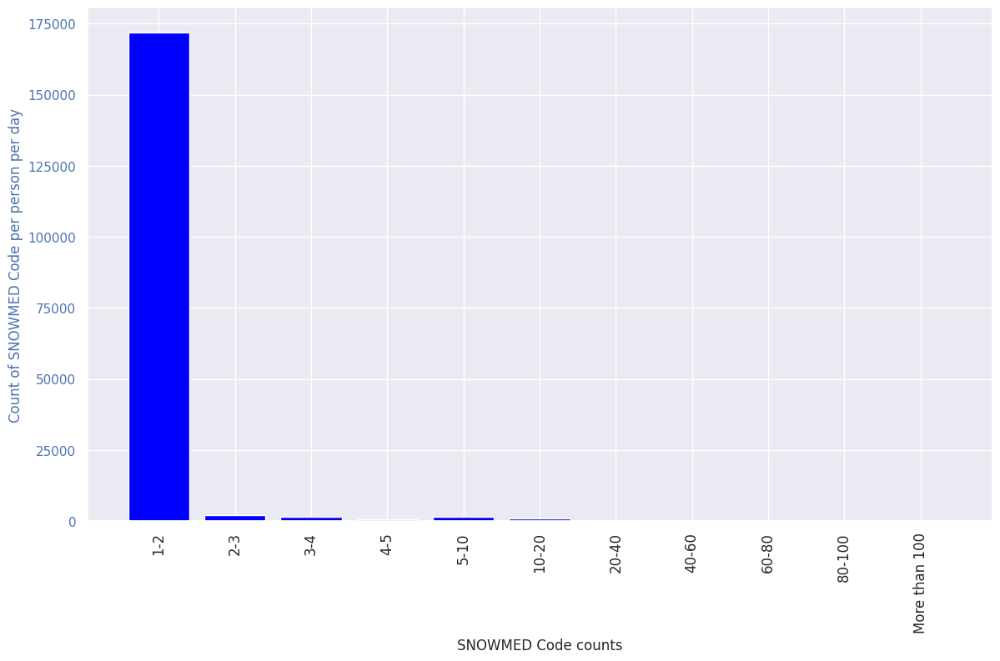

In [10]:
snowmed_counts_distribution = df_mh_day_agg['snowmed_count_range'].value_counts().sort_index()

fig, ax1 = plt.subplots(figsize=(14, 8))

ax1.bar(snowmed_counts_distribution.index.astype(str), snowmed_counts_distribution.values,  color='blue')
ax1.set_xlabel('SNOWMED Code counts')
ax1.set_ylabel('Count of SNOWMED Code per person per day', color='C0')
ax1.tick_params(axis='y', labelcolor='C0')
ax1.tick_params(axis='x', rotation=90, labelsize=12)

# ax2 = ax1.twinx()
# ax2.plot(df_mh_day_agg['snowmed_count_range'], df_mh_day_agg['Cumulative%'], color='C1', marker='D', ms=5)
# ax2.set_ylabel('Cumulative Percentage', color='C1')
# ax2.tick_params(axis='y', labelcolor='C1')

# plt.title('Person counts in Top 70 SNOWMED Codes',fontweight='bold')
plt.show()

## Daily mental health interactions in primary care

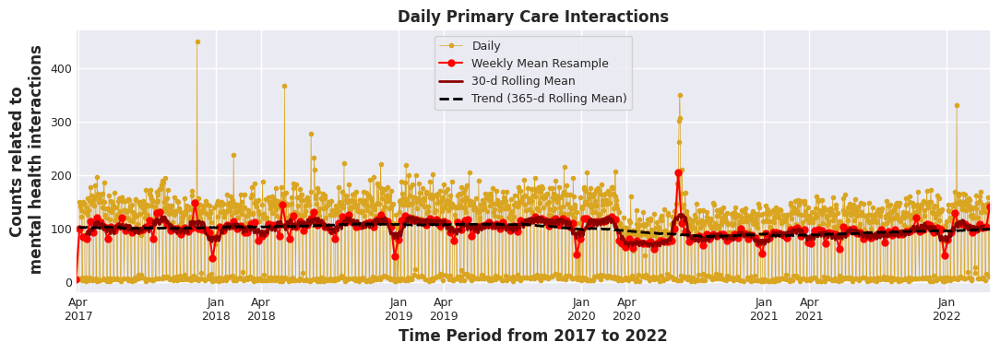

In [11]:
df_mh_day_agg['DateEventRecorded'] = pd.to_datetime(df_mh_day_agg['DateEventRecorded'])
daily_counts = df_mh_day_agg.groupby(df_mh_day_agg['DateEventRecorded'].dt.to_period('D')).size()
weekly_mean = daily_counts.resample('W').mean()
rolling_30d = daily_counts.rolling(30,center=True).mean()
trend = daily_counts.rolling(365,center=True,min_periods=70).mean()

fig, ax = plt.subplots()
daily_counts.plot(ax=ax,marker='.', linestyle='-',linewidth=0.5, label='Daily',color='goldenrod')
weekly_mean.plot(ax=ax,marker='o', markersize=5, linestyle='-', label='Weekly Mean Resample',color='red')
rolling_30d.plot(ax=ax,marker='', linestyle='-', linewidth=2,label='30-d Rolling Mean',color='darkred')
trend.plot(ax=ax,marker='', linestyle='--', linewidth=2,label='Trend (365-d Rolling Mean)',color='black')

ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))

ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.xaxis.set_minor_formatter(mdates.DateFormatter(''))

ax.tick_params(axis='x', pad=-3)
ax.tick_params(axis='y', pad=-3)
ax.legend(prop=tickfont_properties)
plt.xlabel('Time Period from 2017 to 2022',**font_properties)
plt.xticks(**tickfont_properties)
plt.yticks(**tickfont_properties)
plt.ylabel('Counts related to\n mental health interactions',**font_properties)
plt.title('Daily Primary Care Interactions',**font_properties)
fig.tight_layout()

## Monthly mental health interactions in primary care

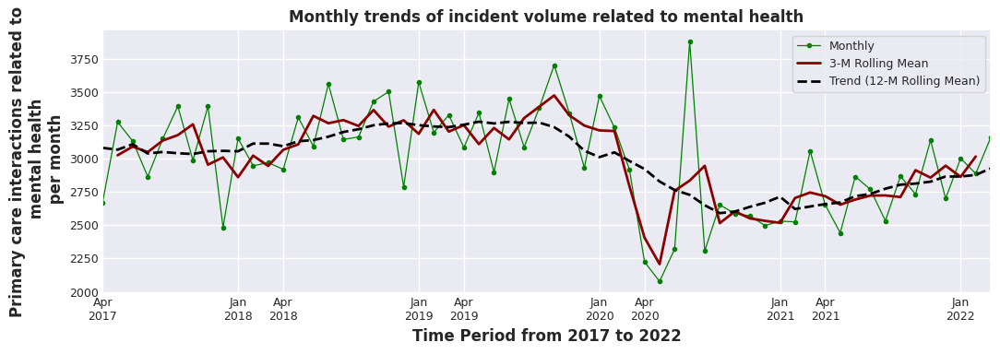

In [12]:
monthly_counts = df_mh_day_agg.groupby(df_mh_day_agg['DateEventRecorded'].dt.to_period('M')).size()
rolling_3m = monthly_counts.rolling(3,center=True).mean()
trend = monthly_counts.rolling(12,center=True,min_periods=3).mean()

dates = monthly_counts.index
tick_dates = [date for date in dates if date.month in [1, 4]]

fig, ax = plt.subplots()
monthly_counts.plot(ax=ax,marker='.', linestyle='-',linewidth=0.9, label='Monthly',color='green')
rolling_3m.plot(ax=ax,marker='', linestyle='-', linewidth=2,label='3-M Rolling Mean',color='darkred')
trend.plot(ax=ax,marker='', linestyle='--', linewidth=2,label='Trend (12-M Rolling Mean)',color='black')

ax.set_xticks(tick_dates)
ax.set_xticklabels([date.strftime('%b\n%Y') for date in tick_dates])

ax.tick_params(axis='x', pad=-3)
ax.tick_params(axis='y', pad=-3)
ax.legend(prop=tickfont_properties)
plt.xlabel('Time Period from 2017 to 2022',**font_properties)
plt.xticks(**tickfont_properties)
plt.yticks(**tickfont_properties)
plt.ylabel('Primary care interactions related to\n mental health\n per month',**font_properties)
plt.title('Monthly trends of incident volume related to mental health',**font_properties)
fig.tight_layout()

In [13]:
# Define conditions and corresponding values to categorise data into the Financial Year
conditions = [
    (df_mh_day_agg.DateEventRecorded.dt.year  == 2017) & (df_mh_day_agg.DateEventRecorded.dt.month.between(4, 12)),
    (df_mh_day_agg.DateEventRecorded.dt.year  == 2018) & (df_mh_day_agg.DateEventRecorded.dt.month.between(1, 3)),
    (df_mh_day_agg.DateEventRecorded.dt.year  == 2018) & (df_mh_day_agg.DateEventRecorded.dt.month.between(4, 12)),
    (df_mh_day_agg.DateEventRecorded.dt.year  == 2019) & (df_mh_day_agg.DateEventRecorded.dt.month.between(1, 3)),
    (df_mh_day_agg.DateEventRecorded.dt.year  == 2019) & (df_mh_day_agg.DateEventRecorded.dt.month.between(4, 12)),
    (df_mh_day_agg.DateEventRecorded.dt.year  == 2020) & (df_mh_day_agg.DateEventRecorded.dt.month.between(1, 3)),
    (df_mh_day_agg.DateEventRecorded.dt.year  == 2020) & (df_mh_day_agg.DateEventRecorded.dt.month.between(4, 12)),
    (df_mh_day_agg.DateEventRecorded.dt.year  == 2021) & (df_mh_day_agg.DateEventRecorded.dt.month.between(1, 3)),
    (df_mh_day_agg.DateEventRecorded.dt.year == 2021) & (df_mh_day_agg.DateEventRecorded.dt.month.between(4, 12)),
    (df_mh_day_agg.DateEventRecorded.dt.year == 2022) & (df_mh_day_agg.DateEventRecorded.dt.month.between(1, 3))]

values = ['17-18', '17-18', '18-19', '18-19', '19-20', '19-20', '20-21', '20-21', '21-22', '21-22']

df_mh_day_agg['YearTrunk'] = np.select(conditions, values, default='Other')

## Temporal Insights with Calendar Heatmaps

A calendar heatmap provides a compact and intuitive way to visualize an entire year of daily data, making it easier to identify temporal patterns and anomalies. In this case, the calendar is aligned with the financial year, starting in April and ending in March. As anticipated, the data reveals a noticeable drop in volume during the COVID-19 lockdown period, followed by a sudden spike on certain days in July. This surge may reflect the overwhelming psychological impact of prolonged isolation, with many individuals seeking mental health support immediately after lockdown restrictions were eased.

(<Figure size 1250x850 with 6 Axes>,
 array([<Axes: ylabel='2017-2018'>, <Axes: ylabel='2018-2019'>,
        <Axes: ylabel='2019-2020'>, <Axes: ylabel='2020-2021'>,
        <Axes: ylabel='2021-2022'>], dtype=object))

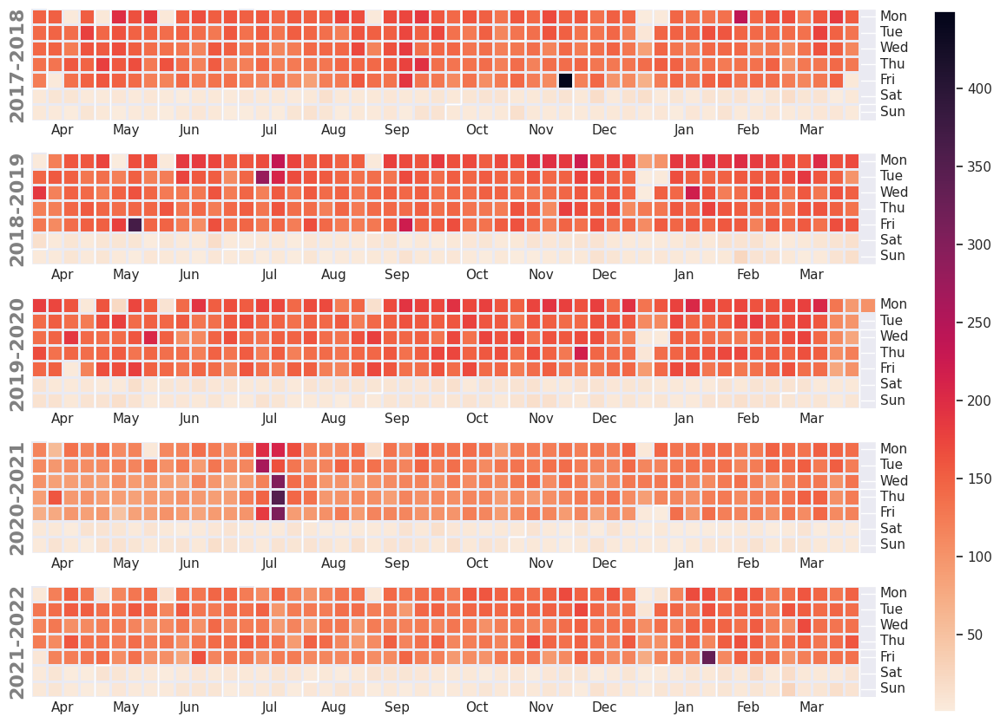

In [14]:
import importlib
import plot_calendar_heatmap
importlib.reload(plot_calendar_heatmap)

df_mh_calendar = df_mh_day_agg.groupby('DateEventRecorded').size()
plot_calendar_heatmap.yearmonthdayplot(df_mh_calendar, edgecolor=None, cmap='rocket_r')

## Weekly Distribution of Mental Health Interaction Volume by Financial Year

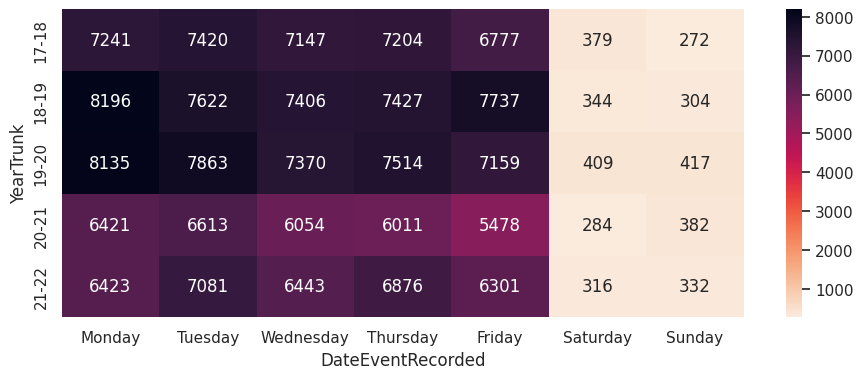

In [15]:
df_mh_day_wise = df_mh_day_agg.groupby(['YearTrunk',df_mh_day_agg['DateEventRecorded'].dt.day_name()]).size().reset_index(name='Volume')
df_mh_day_wise_pivot = df_mh_day_wise.pivot(index='YearTrunk',columns='DateEventRecorded',values='Volume').fillna(0)
correct_day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
df_mh_day_wise_pivot = df_mh_day_wise_pivot[correct_day_order]

sns.heatmap(df_mh_day_wise_pivot, annot=True, fmt="d", cmap="rocket_r")
plt.show()

## Distinct Snowmed codes
We explore the different snowmed codes that exist within the data for the analysis period. There are **778** unique SNOWMED codes. We then visualise the snowmed codes using a pareto chart and observe that 90% of our data lies within the top 70 SNOWMED codes.

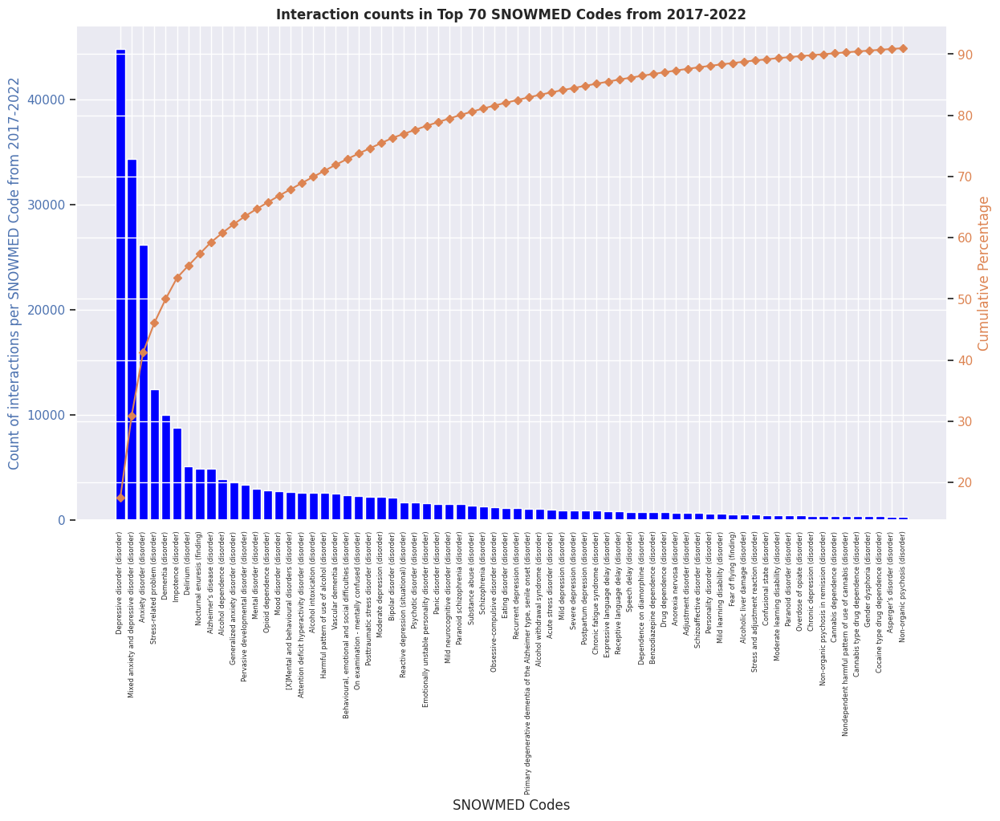

In [16]:
snomed_mh_disorder = pd.read_csv('mental_disorder.csv',index_col=0)
df_mh_all_pid = df_mh_all_pid.merge(snomed_mh_disorder,left_on='SNOMEDCode',right_on='conceptId')
distinct_snomed_counts = df_mh_all_pid['SNOMEDCode'].value_counts().sort_index()
distinct_snomed_counts = distinct_snomed_counts.reset_index().merge(snomed_mh_disorder,left_on='SNOMEDCode',right_on='conceptId')
distinct_snomed_counts = distinct_snomed_counts.sort_values(by='count', ascending=False)
distinct_snomed_counts['Cumulative%'] = distinct_snomed_counts['count'].cumsum() / distinct_snomed_counts['count'].sum() * 100

fig, ax1 = plt.subplots(figsize=(14, 8))

ax1.bar(distinct_snomed_counts[:70]['term'], distinct_snomed_counts[:70]['count'], color='blue')
ax1.set_xlabel('SNOWMED Codes')
ax1.set_ylabel('Count of interactions per SNOWMED Code from 2017-2022', color='C0')
ax1.tick_params(axis='y', labelcolor='C0')
ax1.tick_params(axis='x', rotation=90, labelsize=6)

ax2 = ax1.twinx()
ax2.plot(distinct_snomed_counts[:70]['term'], distinct_snomed_counts[:70]['Cumulative%'], color='C1', marker='D', ms=5)
ax2.set_ylabel('Cumulative Percentage', color='C1')
ax2.tick_params(axis='y', labelcolor='C1')

plt.title('Interaction counts in Top 70 SNOWMED Codes from 2017-2022',fontweight='bold')
plt.show()

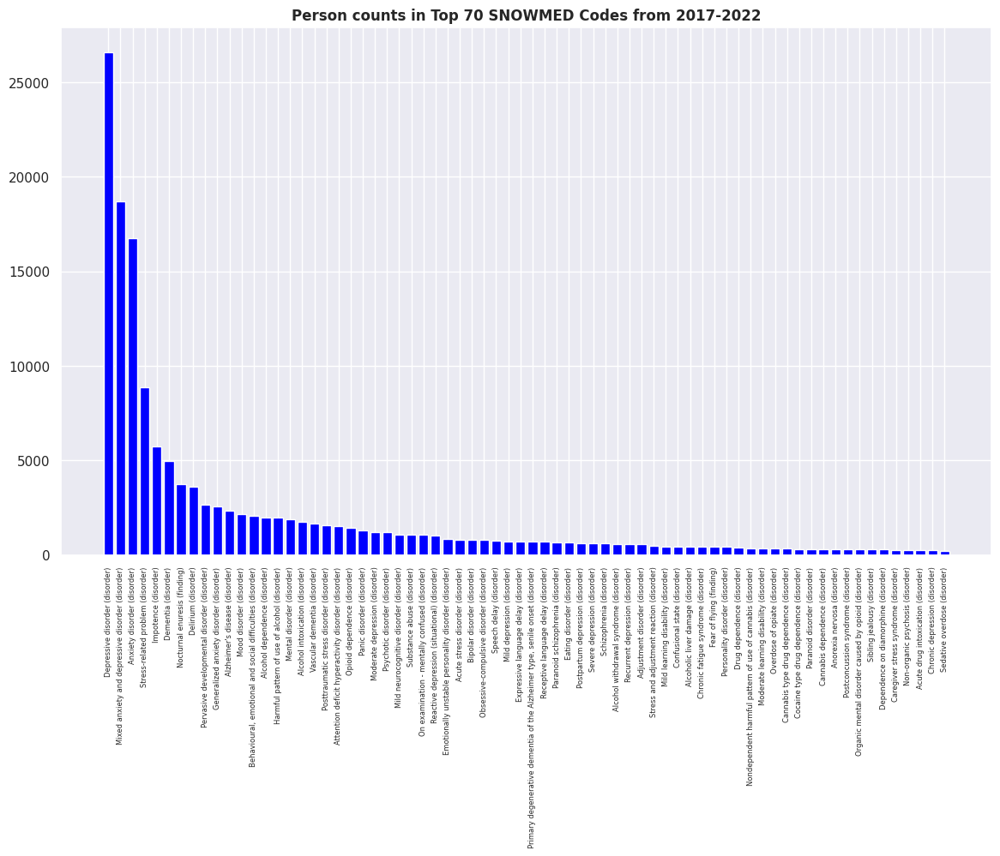

In [17]:
df_mh_smd = df_mh_all_pid.groupby(['SNOMEDCode','person_id_hashed']).size().reset_index(name='Tot_person_interactions')
person_per_smd = df_mh_smd.groupby('SNOMEDCode').size().reset_index(name='personcounts').sort_values(by='personcounts', ascending=False)
person_per_smd = person_per_smd.merge(snomed_mh_disorder,left_on='SNOMEDCode',right_on='conceptId')

fig, ax = plt.subplots(figsize=(14, 8))

ax.bar(person_per_smd[:70]['term'], person_per_smd[:70]['personcounts'], color='blue')
ax.tick_params(axis='x', rotation=90, labelsize=6)

plt.title('Person counts in Top 70 SNOWMED Codes from 2017-2022',fontweight='bold')
plt.show()

# Determining LSOA at Time of Interaction

To determine the most accurate LSOA associated with an individual at the time of a recorded interaction, we used a historical address lookup table containing `DateTo` values that indicate the end date of residence at a given address. The process involved the following steps:

**1. Filtering by Valid Address Period:**<br>
For each interaction, we identified all address records where the `DateTo` was greater than the interaction date, ensuring the address was still valid at the time of the event.

**2. Identifying the Relevant Address Window:**<br>
We then selected the address record where the interaction date fell between the `DateTo` of the previous address and the `DateTo` of the next address in the individual’s address history. This ensured that the selected address accurately reflected the person's location at the time of interaction.

**3. Handling Multiple Matches:**<br>
In cases where multiple address records matched the interaction date (i.e., overlapping or duplicate entries), we selected the last recorded LSOA, assuming that the latest address entry reflects the most accurate and up-to-date information.

In [18]:
query2= """
SELECT cb_date_added, person_id_hashed,SOA,DateTo,DateEventRecorded,PartialPostCode
FROM `yhcr-prd-bradfor-bia-core.CB_2797_PoliceMentalHealth.tbl_SRPatientAddressHistory`
WHERE DATE(DateTo)>=DATE("2014-04-01") AND DATE(DateTo)<=DATE("2025-03-31")
"""

In [19]:
lsoa_df = read_gbq(query2, project_id="yhcr-prd-bradfor-bia-core", use_bqstorage_api=False)
lsoa_df.head(2)

Downloading: 100%|██████████|


,cb_date_added,person_id_hashed,SOA,DateTo,DateEventRecorded,PartialPostCode
0,2022-07-07 22:14:26.750000+00:00,A3056F7C499021657C5195AC09E1BBEECDF03342E47944...,None,2022-05-22 00:00:00+00:00,2022-05-22 11:29:25+00:00,BD22
1,2022-07-07 22:14:26.750000+00:00,31A2033303BC82B04CC1387CDCA2CCC340BBF8F3B926AE...,None,2022-05-27 00:00:00+00:00,2022-05-27 13:32:46+00:00,LS23


In [20]:
lsoa_df_sorted = lsoa_df.sort_values(by=['person_id_hashed', 'DateTo', 'DateEventRecorded'], ascending=[True, True, True])
lsoa_df_sorted['DateTo']=pd.to_datetime(lsoa_df_sorted['DateTo']).dt.tz_localize(None).values.astype("datetime64[D]")
lsoa_df_sorted['DateEventRecorded']=pd.to_datetime(lsoa_df_sorted['DateEventRecorded']).dt.tz_localize(None).values.astype("datetime64[D]")

In [21]:
query3 = """
SELECT person_id_hashed,LSOA
FROM `yhcr-prd-bradfor-bia-core.CB_2797_PoliceMentalHealth.personLSOANew`
WHERE LSOA IS NOT NULL AND LSOA <> ''
"""

In [22]:
curr_lsoa_df = read_gbq(query3, project_id="yhcr-prd-bradfor-bia-core", use_bqstorage_api=False)
curr_lsoa_df.head(2)

Downloading: 100%|██████████|


,person_id_hashed,LSOA
0,8CB8FA3776B384A7FC3C2CD789379B33719E112F10A9DB...,
1,2A588C1C319CB88B789A02BE784FAC6877AF167E967F31...,


In [23]:
lsoa_df_sorted['DateTo'] = lsoa_df_sorted['DateTo'].astype('datetime64[ns]')

In [24]:
df_mh_day_agg['DateEventRecorded'] = pd.to_datetime(df_mh_day_agg['DateEventRecorded'], errors='coerce')
lsoa_df_sorted['DateTo'] = pd.to_datetime(lsoa_df_sorted['DateTo'], errors='coerce')

In [66]:
# Function to process each interaction individually
def get_valid_lsoa(row,lsoa_group_dict,curr_lsoa_df):
    print(row.name)
    person_id = row['person_id_hashed']
    interaction_date = row['DateEventRecorded']
    # reference date is the date when the data was updated in the BigQuery
    reference_date = pd.to_datetime('2025-07-17')

    
    # Check if person exists in the grouped address data
    if person_id not in lsoa_group_dict:
        current_row = curr_lsoa_df[curr_lsoa_df['person_id_hashed'] == person_id]
        if not current_row.empty:
            result_row = current_row.iloc[0]
            return {
                'MostRecent_Previous_LSOA_Code': None,
                'Time_D_prev': None,
                'Confidence_prev': None,
                'Mostrecent_Post_LSOA_Code': result_row['LSOA'],
                'Time_D_after': reference_date-interaction_date,
                'Confidence_after': 3
            }
        else:
            return {'MostRecent_Previous_LSOA_Code': None,'Time_D_prev':None, 'Confidence_prev':None,'Mostrecent_Post_LSOA_Code': None,'Time_D_after':None, 'Confidence_after': None}


    person_addresses = lsoa_group_dict[person_id]
    
    # Filter for addresses valid at the time of interaction
    valid_addresses = person_addresses[person_addresses['DateTo'] > interaction_date]
    valid_addresses_before_interaction= person_addresses[person_addresses['DateTo'] <= interaction_date]

    if not valid_addresses.empty or not valid_addresses_before_interaction.empty:
        # Sort by DateTo and DateEventRecorded
        valid_addresses = valid_addresses.sort_values(by=['DateTo', 'DateEventRecorded'])
        valid_addresses_before_interaction = valid_addresses_before_interaction.sort_values(by=['DateTo', 'DateEventRecorded'])
        
        if not valid_addresses_before_interaction.empty:
            # Check for multiple entries with the same DateTo for previous interactions
            first_date_before = valid_addresses_before_interaction.iloc[-1]['DateTo']
            same_datebefore = valid_addresses_before_interaction[valid_addresses_before_interaction['DateTo'] == first_date_before]

            if len(same_datebefore) == 1:
                confidence_before = 1
                result_row_before = same_datebefore.iloc[0]
                interval_prev = result_row_before['DateTo']-interaction_date
            else:
                confidence_before = 2
                result_row_before = same_datebefore.iloc[-1]
                interval_prev = result_row_before['DateTo']-interaction_date
        else:
            confidence_before = None
            result_row_before = None
            interval_prev = None
        
        if not valid_addresses.empty:
            # Check for multiple entries with the same DateTo for post interactions
            first_date_to = valid_addresses.iloc[0]['DateTo']
            same_dateto = valid_addresses[valid_addresses['DateTo'] == first_date_to]

            if len(same_dateto) == 1:
                confidence_after = 1
                result_row_after = same_dateto.iloc[0]
                interval_after = result_row_after['DateTo']-interaction_date
            else:
                confidence_after = 2
                result_row_after = same_dateto.iloc[-1]
                interval_after = result_row_after['DateTo']-interaction_date
        else:
            confidence_after = None
            result_row_after = None
            interval_after = None

        return {
            'MostRecent_Previous_LSOA_Code': result_row_before['SOA'] if result_row_before is not None else None,
            'Time_D_prev': interval_prev,
            'Confidence_prev': confidence_before,
            'Mostrecent_Post_LSOA_Code': result_row_after['SOA'] if result_row_after is not None else None,
            'Time_D_after': interval_after,
            'Confidence_after': confidence_after
        }
    else:
        return {'MostRecent_Previous_LSOA_Code':None,
            'Time_D_prev': None,
            'Confidence_prev': 7,
            'Mostrecent_Post_LSOA_Code': None,
            'Time_D_after': None,
            'Confidence_prev': 7}

In [ ]:
df_mh_day_agg['DateEventRecorded']=pd.to_datetime(df_mh_day_agg['DateEventRecorded'])
# part_data = df_mh_day_agg.iloc[:70]
# df_mh_day_agg = df_mh_day_agg.reset_index()
df_mh_day_agg[['Valid_LSOA','PartPostCode']] =df_mh_day_agg.apply(get_valid_lsoa,axis=1)

In [23]:
# def process_chunk(chunk):
#     return chunk.apply(get_valid_lsoa, axis=1)

# df_mh_day_agg = df_mh_day_agg.reset_index()
# # Split DataFrame into chunks of 10000 rows
# chunk_size = [0]+[10000]*(179358//10000)+[179358%10000]
# chunks = [df_mh_day_agg.iloc[(i*chunk_size[i]):(i*chunk_size[i]) + chunk_size[i+1]] for i in range(len(chunk_size)-1)]

In [67]:
df_mh_day_agg = df_mh_day_agg.reset_index()
lsoa_group_dict = dict(tuple(lsoa_df_sorted.groupby('person_id_hashed')))
part_data_1 = df_mh_day_agg.iloc[:40000]
results_1 = part_data_1.apply(lambda row: get_valid_lsoa(row, lsoa_group_dict,curr_lsoa_df), axis=1)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

In [68]:
part_data_2 = df_mh_day_agg.iloc[40000:80000]
results_2 = part_data_2.apply(lambda row: get_valid_lsoa(row, lsoa_group_dict,curr_lsoa_df), axis=1)

40000
40001
40002
40003
40004
40005
40006
40007
40008
40009
40010
40011
40012
40013
40014
40015
40016
40017
40018
40019
40020
40021
40022
40023
40024
40025
40026
40027
40028
40029
40030
40031
40032
40033
40034
40035
40036
40037
40038
40039
40040
40041
40042
40043
40044
40045
40046
40047
40048
40049
40050
40051
40052
40053
40054
40055
40056
40057
40058
40059
40060
40061
40062
40063
40064
40065
40066
40067
40068
40069
40070
40071
40072
40073
40074
40075
40076
40077
40078
40079
40080
40081
40082
40083
40084
40085
40086
40087
40088
40089
40090
40091
40092
40093
40094
40095
40096
40097
40098
40099
40100
40101
40102
40103
40104
40105
40106
40107
40108
40109
40110
40111
40112
40113
40114
40115
40116
40117
40118
40119
40120
40121
40122
40123
40124
40125
40126
40127
40128
40129
40130
40131
40132
40133
40134
40135
40136
40137
40138
40139
40140
40141
40142
40143
40144
40145
40146
40147
40148
40149
40150
40151
40152
40153
40154
40155
40156
40157
40158
40159
40160
40161
40162
40163
40164
40165
4016

In [69]:
part_data_3 = df_mh_day_agg.iloc[80000:120000]
results_3 = part_data_3.apply(lambda row: get_valid_lsoa(row, lsoa_group_dict,curr_lsoa_df), axis=1)

80000
80001
80002
80003
80004
80005
80006
80007
80008
80009
80010
80011
80012
80013
80014
80015
80016
80017
80018
80019
80020
80021
80022
80023
80024
80025
80026
80027
80028
80029
80030
80031
80032
80033
80034
80035
80036
80037
80038
80039
80040
80041
80042
80043
80044
80045
80046
80047
80048
80049
80050
80051
80052
80053
80054
80055
80056
80057
80058
80059
80060
80061
80062
80063
80064
80065
80066
80067
80068
80069
80070
80071
80072
80073
80074
80075
80076
80077
80078
80079
80080
80081
80082
80083
80084
80085
80086
80087
80088
80089
80090
80091
80092
80093
80094
80095
80096
80097
80098
80099
80100
80101
80102
80103
80104
80105
80106
80107
80108
80109
80110
80111
80112
80113
80114
80115
80116
80117
80118
80119
80120
80121
80122
80123
80124
80125
80126
80127
80128
80129
80130
80131
80132
80133
80134
80135
80136
80137
80138
80139
80140
80141
80142
80143
80144
80145
80146
80147
80148
80149
80150
80151
80152
80153
80154
80155
80156
80157
80158
80159
80160
80161
80162
80163
80164
80165
8016

In [70]:
part_data_4 = df_mh_day_agg.iloc[120000:160000]
results_4 = part_data_4.apply(lambda row: get_valid_lsoa(row, lsoa_group_dict,curr_lsoa_df), axis=1)

120000
120001
120002
120003
120004
120005
120006
120007
120008
120009
120010
120011
120012
120013
120014
120015
120016
120017
120018
120019
120020
120021
120022
120023
120024
120025
120026
120027
120028
120029
120030
120031
120032
120033
120034
120035
120036
120037
120038
120039
120040
120041
120042
120043
120044
120045
120046
120047
120048
120049
120050
120051
120052
120053
120054
120055
120056
120057
120058
120059
120060
120061
120062
120063
120064
120065
120066
120067
120068
120069
120070
120071
120072
120073
120074
120075
120076
120077
120078
120079
120080
120081
120082
120083
120084
120085
120086
120087
120088
120089
120090
120091
120092
120093
120094
120095
120096
120097
120098
120099
120100
120101
120102
120103
120104
120105
120106
120107
120108
120109
120110
120111
120112
120113
120114
120115
120116
120117
120118
120119
120120
120121
120122
120123
120124
120125
120126
120127
120128
120129
120130
120131
120132
120133
120134
120135
120136
120137
120138
120139
120140
120141
120142

In [71]:
part_data_5 = df_mh_day_agg.iloc[160000:]
results_5 = part_data_5.apply(lambda row: get_valid_lsoa(row, lsoa_group_dict,curr_lsoa_df), axis=1)

160000
160001
160002
160003
160004
160005
160006
160007
160008
160009
160010
160011
160012
160013
160014
160015
160016
160017
160018
160019
160020
160021
160022
160023
160024
160025
160026
160027
160028
160029
160030
160031
160032
160033
160034
160035
160036
160037
160038
160039
160040
160041
160042
160043
160044
160045
160046
160047
160048
160049
160050
160051
160052
160053
160054
160055
160056
160057
160058
160059
160060
160061
160062
160063
160064
160065
160066
160067
160068
160069
160070
160071
160072
160073
160074
160075
160076
160077
160078
160079
160080
160081
160082
160083
160084
160085
160086
160087
160088
160089
160090
160091
160092
160093
160094
160095
160096
160097
160098
160099
160100
160101
160102
160103
160104
160105
160106
160107
160108
160109
160110
160111
160112
160113
160114
160115
160116
160117
160118
160119
160120
160121
160122
160123
160124
160125
160126
160127
160128
160129
160130
160131
160132
160133
160134
160135
160136
160137
160138
160139
160140
160141
160142

In [72]:
results_1 = pd.DataFrame(results_1.to_list())
results_2 = pd.DataFrame(results_2.to_list())
results_3 = pd.DataFrame(results_3.to_list())
results_4 = pd.DataFrame(results_4.to_list())
results_5 = pd.DataFrame(results_5.to_list())
merged_results = pd.concat([results_1,results_2,results_3,results_4,results_5],axis=0)
merged_results.tail(2)

,MostRecent_Previous_LSOA_Code,Time_D_prev,Confidence_prev,Mostrecent_Post_LSOA_Code,Time_D_after,Confidence_after
19356,None,NaT,NaN,E01027585,273 days,1.0
19357,E01010653,-164 days,1.0,E01010779,2061 days,2.0


In [76]:
merged_results = merged_results.reset_index(drop=True)
df_mh_day_agg_lsoa = pd.concat([df_mh_day_agg,merged_results],axis=1)

In [77]:
time_d_after_days = df_mh_day_agg_lsoa['Time_D_after'].dt.days.fillna(np.inf)
time_d_prev_days = df_mh_day_agg_lsoa['Time_D_prev'].dt.days.abs().fillna(np.inf)
condition = time_d_after_days > time_d_prev_days
df_mh_day_agg_lsoa['Assigned_LSOA'] = np.where(condition,df_mh_day_agg_lsoa['MostRecent_Previous_LSOA_Code'],df_mh_day_agg_lsoa['Mostrecent_Post_LSOA_Code'])
df_mh_day_agg_lsoa['Assigned_confidence'] = np.where(condition,df_mh_day_agg_lsoa['Confidence_prev'],df_mh_day_agg_lsoa['Confidence_after'])

In [86]:
condition_2 = df_mh_day_agg_lsoa_bd['Time_D_after'].dt.days > abs(df_mh_day_agg_lsoa_bd['Time_D_prev'].dt.days)
df_mh_day_agg_lsoa_bd['Assigned_address_interval'] = np.where(condition_2,abs(df_mh_day_agg_lsoa_bd['Time_D_prev'].dt.days),df_mh_day_agg_lsoa_bd['Time_D_after'].dt.days)
df_mh_day_agg_lsoa_bd

,index,person_id_hashed,DateEventRecorded,Count,Cumulative%,snowmed_count_range,YearTrunk,MostRecent_Previous_LSOA_Code,Time_D_prev,Confidence_prev,Mostrecent_Post_LSOA_Code,Time_D_after,Confidence_after,Assigned_LSOA,Assigned_confidence,Assigned_address_interval
3,35256,31E8B8FCE7B6BD8018337BB35EDA473F996FB3FBB1CF44...,2017-04-20,272,0.481607,More than 100,17-18,E01010687,-1 days,1.0,E01010687,74 days,1.0,E01010687,1.0,1.0
7,15319,155079698FB961A39D05977C81BD1B9A93FBE87777F1A9...,2020-05-06,210,0.844574,More than 100,20-21,E01010782,0 days,1.0,E01019236,82 days,1.0,E01010782,1.0,0.0
9,34449,30B5B33FD66E80DC3A08F26716ACB3D5A8AC251B8F81C5...,2021-08-16,194,1.000411,More than 100,21-22,E01010755,-3 days,2.0,E01010823,4 days,1.0,E01010755,2.0,3.0
14,27122,262056A9F7875FFE5C2799644113ED98B29EC19509287A...,2018-05-18,159,1.335970,More than 100,18-19,E01010627,-262 days,1.0,E01010627,463 days,1.0,E01010627,1.0,262.0
15,132506,BD2DF2FED8466AC8B0A2C9C20281ABFCE79D3B84965F16...,2017-07-06,152,1.395485,More than 100,17-18,E01010705,-1 days,1.0,E01010705,1161 days,1.0,E01010705,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
179347,64272,5BAFE06C958D4150EFCCF98841D27B5E61A9A5E35EB92C...,2021-01-08,1,99.996084,1-2,20-21,E01010648,-226 days,1.0,E01010647,1445 days,1.0,E01010648,1.0,226.0
179348,64274,5BB1DF28AA7681645EEFD1B60EC5D3AFC7ED915CDAA2F1...,2019-05-30,1,99.996476,1-2,19-20,E01010752,-828 days,2.0,E01010752,1574 days,1.0,E01010752,2.0,828.0
179349,64283,5BB318B1739FE48DF1D3B6CAFA274E02B7363B8B0AC865...,2019-01-29,1,99.996868,1-2,18-19,None,NaT,NaN,E01010855,2361 days,3.0,E01010855,3.0,2361.0
179355,64280,5BB2C3F9F89415606619DA5A95FB12ACB10F6AFFC0A155...,2018-11-16,1,99.999217,1-2,18-19,None,NaT,NaN,E01010623,2435 days,3.0,E01010623,3.0,2435.0


In [78]:
df_mh_day_agg_lsoa['Assigned_LSOA']=df_mh_day_agg_lsoa['Assigned_LSOA'].replace('',np.nan)
df_mh_day_agg_lsoa['Assigned_confidence']=np.where(df_mh_day_agg_lsoa['Assigned_LSOA'].isnull(),4,df_mh_day_agg_lsoa['Assigned_confidence'])
df_agg_lsoa_count = df_mh_day_agg_lsoa.groupby(['person_id_hashed','DateEventRecorded'])['Assigned_LSOA'].nunique().reset_index(name='Count_lsoa')
df_agg_lsoa_count['Count_lsoa'].value_counts()

Count_lsoa
1    159811
0     19547
Name: count, dtype: int64

In [79]:
df_mh_day_agg_lsoa['Assigned_confidence'].value_counts()

Assigned_confidence
1.0    103459
2.0     36582
3.0     19770
4.0     19547
Name: count, dtype: int64

In [30]:
# person_id_address_history = lsoa_df_sorted['person_id_hashed'].unique()
# df_agg_lsoa_count_filter = df_agg_lsoa_count[df_agg_lsoa_count['person_id_hashed'].isin(person_id_address_history)]
# df_agg_lsoa_count_filter['Count_lsoa'].value_counts()

Count_lsoa
1    113920
0     45136
Name: count, dtype: int64

After joining the GP interactions data with the address history data, it is observed that there are <font color='blue'>**113,920**</font> records which contains the LSOA history of the individual. However, there is no information on LSOA history available for <font color='red'>**65,438**</font> records (<u>36% of the GP records</u>). Now, based on information obtained from Connected Bradford, **1,054** individuals do not have address history records. If we filter the joined dataset based on the unique person ids present in the address history dataset, we observe that there are still <font color='red'>**45,136**</font> records (<u>28% of the filtered GP records</u>) for which there is no information on the LSOA.

In [81]:
# df_mh_day_agg_lsoa_filter = df_mh_day_agg_lsoa[df_mh_day_agg_lsoa['person_id_hashed'].isin(person_id_address_history)]
df_mh_day_agg_lsoa_filter = df_mh_day_agg_lsoa.dropna(subset='Assigned_LSOA')
unique_historic_lsoas = df_mh_day_agg_lsoa_filter['Assigned_LSOA'].unique()
len(unique_historic_lsoas)

7571

**Get the LSOA codes in Bradford**

In [82]:
import geopandas as gpd

all_lsoa = gpd.read_file('LSOA_2011_full.geojson')
df_lsoa_bradford = all_lsoa[all_lsoa.LSOA11NM.str.contains("Bradford")]

In [83]:
df_mh_day_agg_lsoa_bd = df_mh_day_agg_lsoa_filter[df_mh_day_agg_lsoa_filter.Assigned_LSOA.isin(df_lsoa_bradford.LSOA11CD)]
df_mh_day_agg_lsoa_bd.shape

(109513, 15)

In [102]:
(len(df_mh_day_agg) - 109513)/len(df_mh_day_agg)

0.3894166973315938

In [162]:
df_mh_day_agg_lsoa.to_csv('GPinteractions_withLSOA.csv')

We are losing nearly <font color='blue'>**19,547**</font> observations due to no LSOA information either in the current address history or in the previous address history. Therefore, the total number of observations with LSOA information (both current and previous) is <font color='blue'>**159,811**</font>. However, upon restricting the dataset to LSOAs located within Bradford, the number of resulting observations is limited to <font color='blue'>**109,513**</font> thereby losing out on <font color='blue'>**50,298**</font> observations. Hence, we are losing about <font color='red'>**11%**</font> of the data due to no information on LSOA and nearly <font color='red'>**28%**</font> of the data (<u>total observations= **179,358**</u>) as the interaction is occurring outside our study area (Bradford).

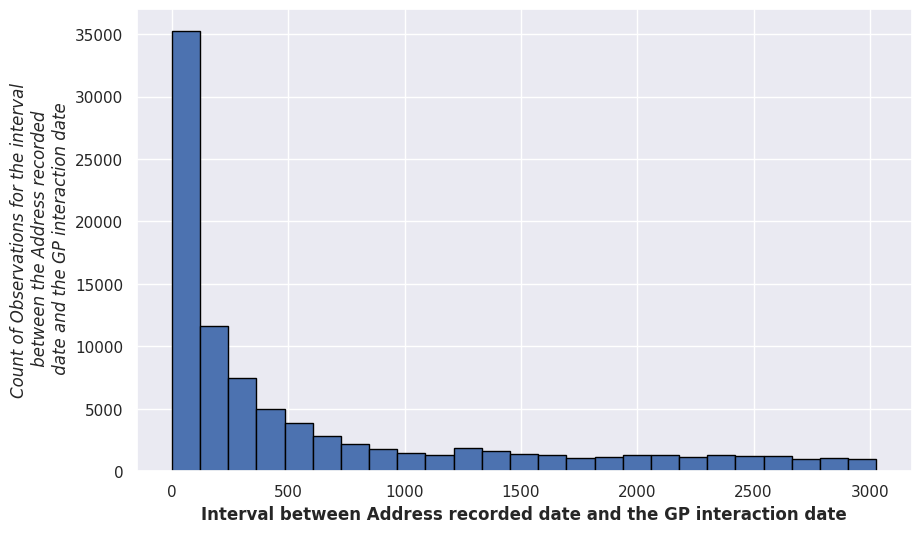

In [100]:
# Plot the distribution
plt.figure(figsize=(10, 6))
plt.hist(df_mh_day_agg_lsoa_bd['Assigned_address_interval'], bins=25, edgecolor='black')

plt.xlabel('Interval between Address recorded date and the GP interaction date',fontweight='bold')
plt.ylabel('Count of Observations for the interval\n between the Address recorded\n date and the GP interaction date',fontstyle='italic')

plt.show()

In [119]:
# df_mh_day_agg_lsoa_bd.melt(
#     id_vars=['person_id_hashed', 'DateEventRecorded','Address_interval_range'],
#     value_vars=['Assigned_confidence'],
#     var_name='Count_Type',
#     value_name='Value'
# )
bins = [-1,0, 5, 10, 30, 100, 200, 300, float('inf')] 
labels = ['0','0-5', '5-10', '10-30', '30-100', '100-200','200-300','300+']

pd.cut(df_mh_day_agg_lsoa_bd['Assigned_address_interval'], bins=bins, labels=labels, right=True)

3             0-5
7               0
9             0-5
14        200-300
15            0-5
           ...   
179347    200-300
179348       300+
179349       300+
179355       300+
179357    100-200
Name: Assigned_address_interval, Length: 109513, dtype: category
Categories (8, object): ['0' < '0-5' < '5-10' < '10-30' < '30-100' < '100-200' < '200-300' < '300+']

# Distribution of address recording intervals

To better understand the variation in the interval between a person’s address to be recorded after a GP (doctor) interaction, I grouped these time intervals into categories. These categories range from very short interval (like 0 days) to very long ones (over 300 days). Each group has a label like "1–5 days" or "101–200 days".

Next, I reshaped the data so that I could look at how confident we are about each LSOA being correctly assigned to a date of interaction. This confidence level is shown alongside the time interval categories.

I then created a bar plot that shows how many observations fall into each time interval category, and how confident we are about each one. The bars are color-coded based on confidence levels.

It helps us quickly see patterns in how address recording intervals vary and how reliable the LSOA assignments are.

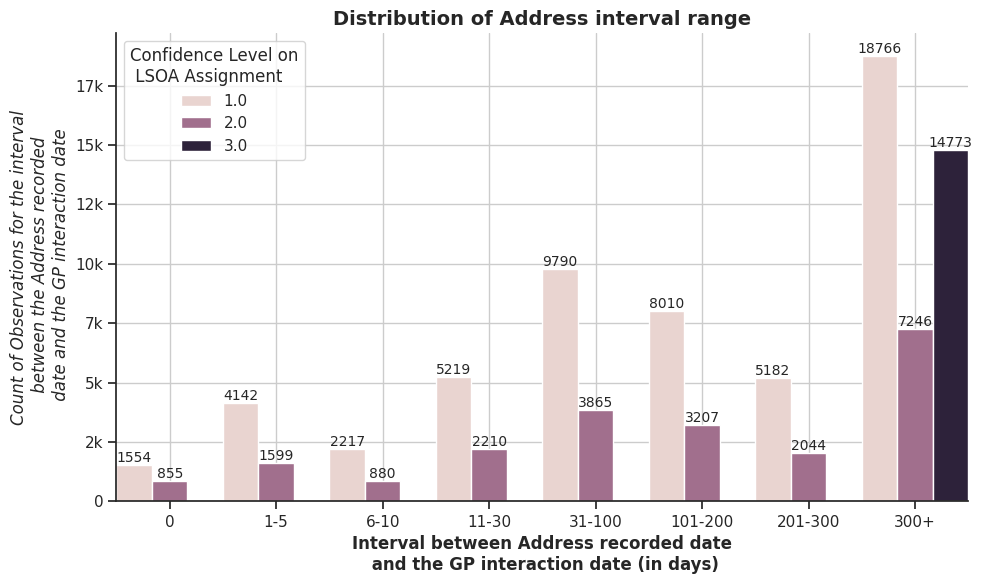

In [133]:
sns.set_style("ticks")
bins = [-1,0, 5, 10, 30, 100, 200, 300, float('inf')] 
labels = ['0','1-5', '6-10', '11-30', '31-100', '101-200','201-300','300+']

df_mh_day_agg_lsoa_bd['Address_interval_range'] = pd.cut(df_mh_day_agg_lsoa_bd['Assigned_address_interval'], bins=bins, labels=labels, right=True)

from matplotlib.ticker import FuncFormatter

df_mh_day_agg_lsoa_bd_melted = df_mh_day_agg_lsoa_bd.melt(
    id_vars=['person_id_hashed', 'DateEventRecorded','Address_interval_range'],
    value_vars=['Assigned_confidence'],
    var_name='Count_Type',
    value_name='Value'
)

plt.figure(figsize=(10, 6))
ax = sns.countplot(
    data=df_mh_day_agg_lsoa_bd_melted,
    x='Address_interval_range',
    hue='Value',
    order=labels,
    width=1.0
)

for container in ax.containers:
    ax.bar_label(container, label_type='edge', fontsize=10)

ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(x/1000)}k' if x >= 1000 else str(int(x))))
sns.despine()
plt.title('Distribution of Address interval range',fontweight='bold',fontsize=14)
plt.xlabel('Interval between Address recorded date\n and the GP interaction date (in days)',fontweight='bold')
plt.ylabel('Count of Observations for the interval\n between the Address recorded\n date and the GP interaction date',fontstyle='italic')
plt.legend(title='Confidence Level on\n LSOA Assignment')
plt.grid()
plt.tight_layout()
plt.show()

# plt.figure(figsize=(10, 6))
# bin_counts.plot(kind='bar', color='royalblue', edgecolor='black',width=0.7)

# # for container in ax.containers:
# #     ax.bar_label(container, label_type='edge', fontsize=10)

# # ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(x/1000)}k' if x >= 1000 else str(int(x))))
# plt.title('Distribution of Address interval range',fontweight='bold')
# plt.xticks(rotation=0)
# plt.xlabel('Interval between Address recorded date\n and the GP interaction date (in days)',fontweight='bold')
# plt.ylabel('Count of Observations for the interval\n between the Address recorded\n date and the GP interaction date',fontstyle='italic')
# # plt.legend(title='Types of LSOA counts')
# plt.tight_layout()
# plt.show()

After the data is filtered to only contain the interactions that took place within Bradford, we have only <font color='blue'>**79,357**</font> observations.

# Considering all the confidence Levels

In [154]:
# Group by 'LSOA' and 'YearTrunk' and count the number of rows per group
interaction_volume = df_mh_day_agg_lsoa_bd.groupby(['Assigned_LSOA', 'YearTrunk']).size().reset_index(name='InteractionVol')

# Pivot the table
interaction_volume_wide = interaction_volume.pivot(index='Assigned_LSOA', columns='YearTrunk', values='InteractionVol').fillna(0)

# Compute 'Total' column summing across specific year columns
interaction_volume_wide['Total'] = interaction_volume_wide[['17-18', '18-19', '19-20', '20-21', '21-22']].sum(axis=1)
summary_row = interaction_volume_wide[['17-18', '18-19', '19-20', '20-21', '21-22','Total']].sum(axis=0)

interaction_volume_wide = pd.concat([interaction_volume_wide, pd.DataFrame(summary_row).T], ignore_index=False)
interaction_volume_wide.rename(index={0:'Column Total'},inplace=True)

In [155]:
interaction_volume_wide_sorted = interaction_volume_wide.sort_values(by='Total',ascending=False)[1:].reset_index()
interaction_volume_wide_sorted.rename(columns={'index':'LSOA'},inplace=True)

interaction_volume_wide_sorted = interaction_volume_wide_sorted.merge(df_lsoa_bradford[['LSOA11CD','geometry']], left_on='LSOA',right_on='LSOA11CD')

gdf_interaction_volume = gpd.GeoDataFrame(interaction_volume_wide_sorted,geometry=interaction_volume_wide_sorted['geometry'])

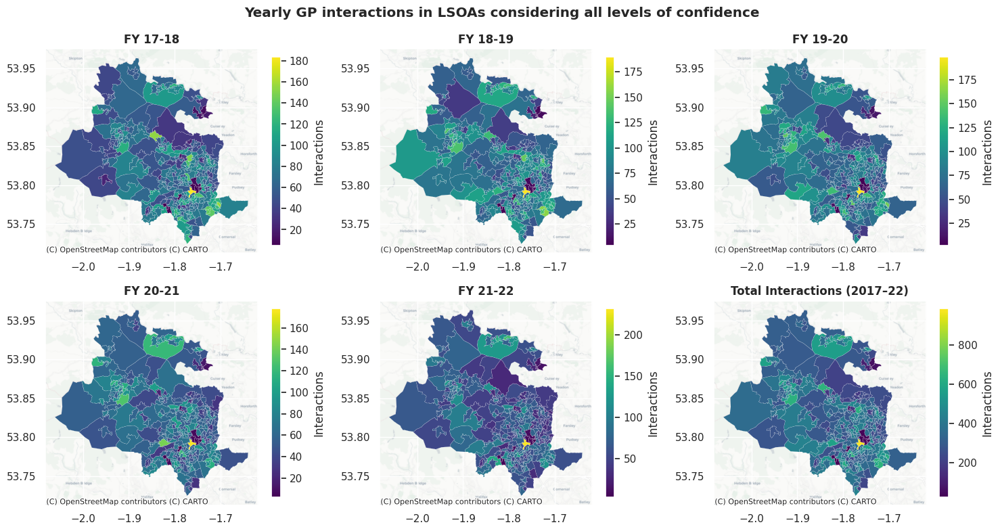

In [156]:
sns.set_theme()

columns = ['17-18', '18-19', '19-20', '20-21', '21-22', 'Total']
titles = ['FY 17-18', 'FY 18-19', 'FY 19-20', 'FY 20-21', 'FY 21-22', 'Total Interactions (2017–22)']

# Create chloropleth maps for interaction counts
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column, title in zip(axes.flatten(), columns, titles):
    gdf_interaction_volume.plot(
        column=column,
        cmap='viridis',
        ax=ax,
        linewidth=0.1,
        legend=True,
        legend_kwds={'label': "Interactions", 'orientation': "vertical", 'shrink': 0.87}
    )
    ax.set_title(title,fontweight='bold')
    cx.add_basemap(ax, crs=gdf_interaction_volume.crs.to_string(), source=cx.providers.CartoDB.Positron)


# Show the plot
plt.suptitle('Yearly GP interactions in LSOAs considering all levels of confidence',fontweight='bold')
plt.tight_layout()
plt.show()

# Considering Confidence Level = 1

In [151]:
df_mh_day_agg_lsoa_conf_1 = df_mh_day_agg_lsoa_bd[df_mh_day_agg_lsoa_bd['Assigned_confidence']==1]
# Group by 'LSOA' and 'YearTrunk' and count the number of rows per group
interaction_volume = df_mh_day_agg_lsoa_conf_1.groupby(['Assigned_LSOA', 'YearTrunk']).size().reset_index(name='InteractionVol')

# Pivot the table
interaction_volume_wide = interaction_volume.pivot(index='Assigned_LSOA', columns='YearTrunk', values='InteractionVol').fillna(0)

# Compute 'Total' column summing across specific year columns
interaction_volume_wide['Total'] = interaction_volume_wide[['17-18', '18-19', '19-20', '20-21', '21-22']].sum(axis=1)
summary_row = interaction_volume_wide[['17-18', '18-19', '19-20', '20-21', '21-22','Total']].sum(axis=0)

interaction_volume_wide = pd.concat([interaction_volume_wide, pd.DataFrame(summary_row).T], ignore_index=False)
interaction_volume_wide.rename(index={0:'Column Total'},inplace=True)

In [152]:
interaction_volume_wide_sorted = interaction_volume_wide.sort_values(by='Total',ascending=False)[1:].reset_index()
interaction_volume_wide_sorted.rename(columns={'index':'LSOA'},inplace=True)

interaction_volume_wide_sorted = interaction_volume_wide_sorted.merge(df_lsoa_bradford[['LSOA11CD','geometry']], left_on='LSOA',right_on='LSOA11CD')

gdf_interaction_volume = gpd.GeoDataFrame(interaction_volume_wide_sorted,geometry=interaction_volume_wide_sorted['geometry'])

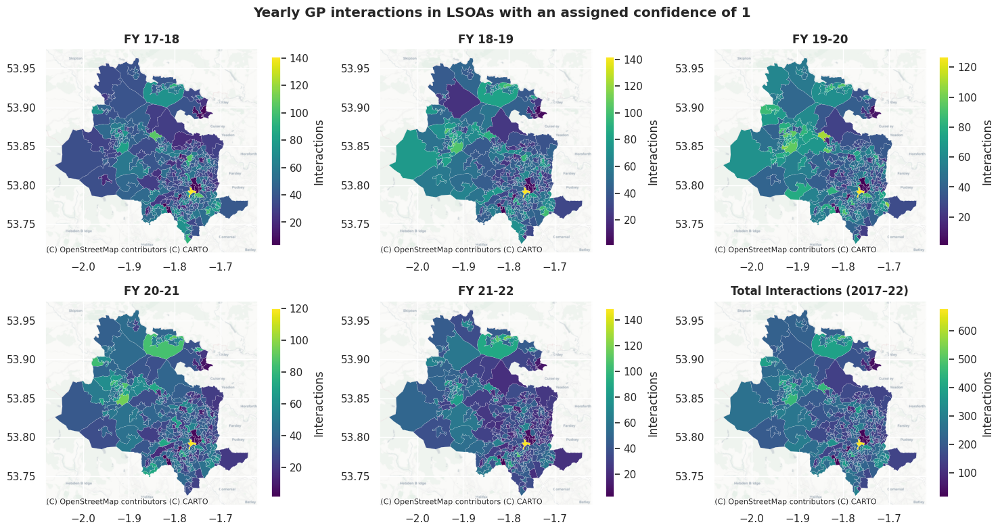

In [153]:
sns.set_theme()

columns = ['17-18', '18-19', '19-20', '20-21', '21-22', 'Total']
titles = ['FY 17-18', 'FY 18-19', 'FY 19-20', 'FY 20-21', 'FY 21-22', 'Total Interactions (2017–22)']

# Create chloropleth maps for interaction counts
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column, title in zip(axes.flatten(), columns, titles):
    gdf_interaction_volume.plot(
        column=column,
        cmap='viridis',
        ax=ax,
        linewidth=0.1,
        legend=True,
        legend_kwds={'label': "Interactions", 'orientation': "vertical", 'shrink': 0.87}
    )
    ax.set_title(title,fontweight='bold')
    cx.add_basemap(ax, crs=gdf_interaction_volume.crs.to_string(), source=cx.providers.CartoDB.Positron)


# Show the plot
plt.suptitle('Yearly GP interactions in LSOAs with an assigned confidence of 1',fontweight='bold')
plt.tight_layout()
plt.show()

# Considering Confidence Level = 2

In [148]:
df_mh_day_agg_lsoa_conf_2 = df_mh_day_agg_lsoa_bd[df_mh_day_agg_lsoa_bd['Assigned_confidence']==2]
# Group by 'LSOA' and 'YearTrunk' and count the number of rows per group
interaction_volume = df_mh_day_agg_lsoa_conf_2.groupby(['Assigned_LSOA', 'YearTrunk']).size().reset_index(name='InteractionVol')

# Pivot the table
interaction_volume_wide = interaction_volume.pivot(index='Assigned_LSOA', columns='YearTrunk', values='InteractionVol').fillna(0)

# Compute 'Total' column summing across specific year columns
interaction_volume_wide['Total'] = interaction_volume_wide[['17-18', '18-19', '19-20', '20-21', '21-22']].sum(axis=1)
summary_row = interaction_volume_wide[['17-18', '18-19', '19-20', '20-21', '21-22','Total']].sum(axis=0)

interaction_volume_wide = pd.concat([interaction_volume_wide, pd.DataFrame(summary_row).T], ignore_index=False)
interaction_volume_wide.rename(index={0:'Column Total'},inplace=True)

In [149]:
interaction_volume_wide_sorted = interaction_volume_wide.sort_values(by='Total',ascending=False)[1:].reset_index()
interaction_volume_wide_sorted.rename(columns={'index':'LSOA'},inplace=True)

interaction_volume_wide_sorted = interaction_volume_wide_sorted.merge(df_lsoa_bradford[['LSOA11CD','geometry']], left_on='LSOA',right_on='LSOA11CD')

gdf_interaction_volume = gpd.GeoDataFrame(interaction_volume_wide_sorted,geometry=interaction_volume_wide_sorted['geometry'])

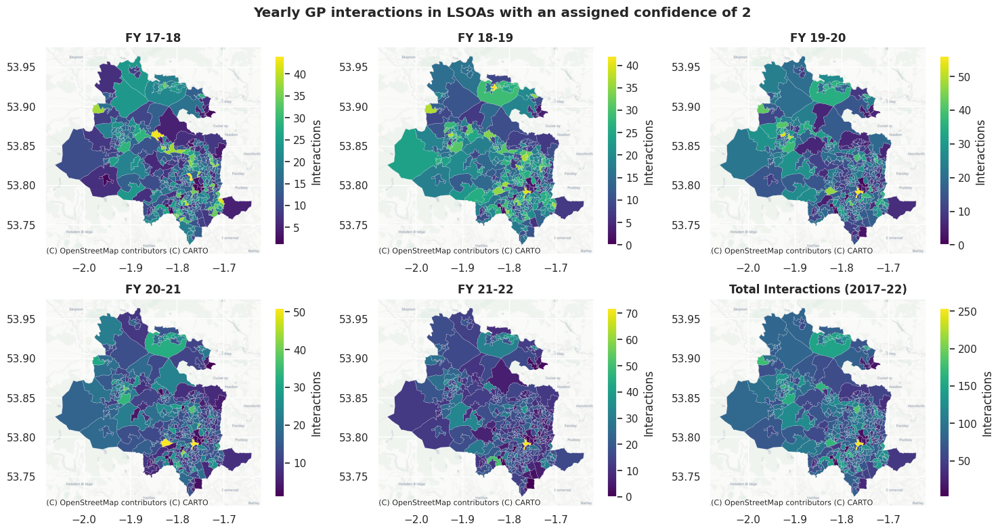

In [150]:
sns.set_theme()

columns = ['17-18', '18-19', '19-20', '20-21', '21-22', 'Total']
titles = ['FY 17-18', 'FY 18-19', 'FY 19-20', 'FY 20-21', 'FY 21-22', 'Total Interactions (2017–22)']

# Create chloropleth maps for interaction counts
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column, title in zip(axes.flatten(), columns, titles):
    gdf_interaction_volume.plot(
        column=column,
        cmap='viridis',
        ax=ax,
        linewidth=0.1,
        legend=True,
        legend_kwds={'label': "Interactions", 'orientation': "vertical", 'shrink': 0.87}
    )
    ax.set_title(title,fontweight='bold')
    cx.add_basemap(ax, crs=gdf_interaction_volume.crs.to_string(), source=cx.providers.CartoDB.Positron)


# Show the plot
plt.suptitle('Yearly GP interactions in LSOAs with an assigned confidence of 2',fontweight='bold')
plt.tight_layout()
plt.show()

# Considering Confidence Level = 3

In [145]:
df_mh_day_agg_lsoa_conf_3 = df_mh_day_agg_lsoa_bd[df_mh_day_agg_lsoa_bd['Assigned_confidence']==3]
# Group by 'LSOA' and 'YearTrunk' and count the number of rows per group
interaction_volume = df_mh_day_agg_lsoa_conf_3.groupby(['Assigned_LSOA', 'YearTrunk']).size().reset_index(name='InteractionVol')

# Pivot the table
interaction_volume_wide = interaction_volume.pivot(index='Assigned_LSOA', columns='YearTrunk', values='InteractionVol').fillna(0)

# Compute 'Total' column summing across specific year columns
interaction_volume_wide['Total'] = interaction_volume_wide[['17-18', '18-19', '19-20', '20-21', '21-22']].sum(axis=1)
summary_row = interaction_volume_wide[['17-18', '18-19', '19-20', '20-21', '21-22','Total']].sum(axis=0)

interaction_volume_wide = pd.concat([interaction_volume_wide, pd.DataFrame(summary_row).T], ignore_index=False)
interaction_volume_wide.rename(index={0:'Column Total'},inplace=True)

In [146]:
interaction_volume_wide_sorted = interaction_volume_wide.sort_values(by='Total',ascending=False)[1:].reset_index()
interaction_volume_wide_sorted.rename(columns={'index':'LSOA'},inplace=True)

interaction_volume_wide_sorted = interaction_volume_wide_sorted.merge(df_lsoa_bradford[['LSOA11CD','geometry']], left_on='LSOA',right_on='LSOA11CD')

gdf_interaction_volume = gpd.GeoDataFrame(interaction_volume_wide_sorted,geometry=interaction_volume_wide_sorted['geometry'])

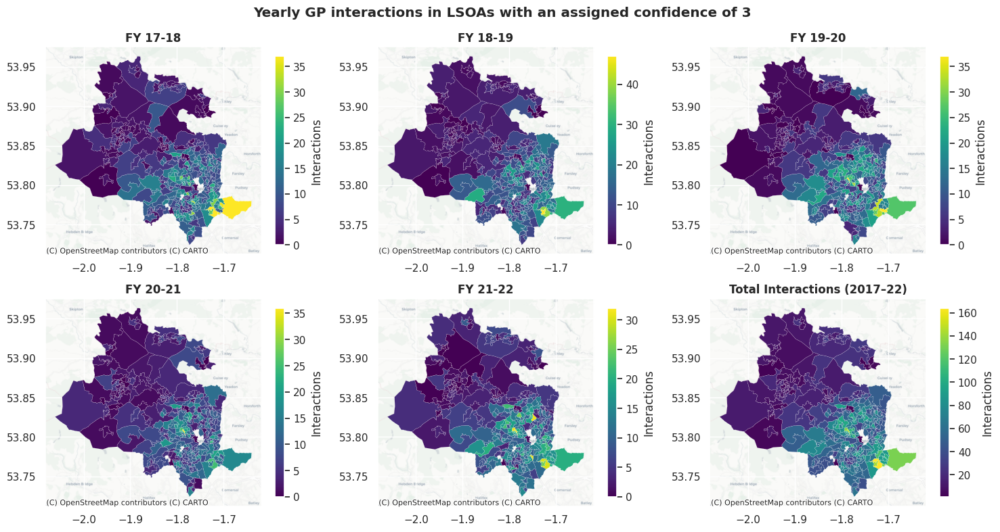

In [147]:
sns.set_theme()

columns = ['17-18', '18-19', '19-20', '20-21', '21-22', 'Total']
titles = ['FY 17-18', 'FY 18-19', 'FY 19-20', 'FY 20-21', 'FY 21-22', 'Total Interactions (2017–22)']

# Create chloropleth maps for interaction counts
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column, title in zip(axes.flatten(), columns, titles):
    gdf_interaction_volume.plot(
        column=column,
        cmap='viridis',
        ax=ax,
        linewidth=0.1,
        legend=True,
        legend_kwds={'label': "Interactions", 'orientation': "vertical", 'shrink': 0.87}
    )
    ax.set_title(title,fontweight='bold')
    cx.add_basemap(ax, crs=gdf_interaction_volume.crs.to_string(), source=cx.providers.CartoDB.Positron)


# Show the plot
plt.suptitle('Yearly GP interactions in LSOAs with an assigned confidence of 3',fontweight='bold')
plt.tight_layout()
plt.show()

In [63]:
import branca.colormap as cm
import folium

# Create a folium map centered on the data
m = folium.Map(location=[gdf_interaction_volume.geometry.centroid.y.mean(),
                         gdf_interaction_volume.geometry.centroid.x.mean()],
               zoom_start=11, tiles='cartodbpositron')

columns = ['17-18', '18-19', '19-20', '20-21', '21-22', 'Total']
titles = ['FY 17-18', 'FY 18-19', 'FY 19-20', 'FY 20-21', 'FY 21-22', 'Total Interactions (2017–22)']

# Create a colormap
# colormap = cm.linear.YlGnBu_09.scale(gdf_interaction_volume[columns].min().min(),gdf_interaction_volume[columns].max().max()).reverse()
# colormap = cm.LinearColormap(
#     colors=list(cm.linear.YlGnBu_09.colors)[::-1],
#     vmin=gdf_interaction_volume[columns].min().min(),
#     vmax=gdf_interaction_volume[columns].max().max()
# )
year_colormaps = {
    '17-18': cm.LinearColormap(
    colors=list(cm.linear.YlGnBu_09.colors)[::-1],
    vmin=gdf_interaction_volume['17-18'].min(),
    vmax=gdf_interaction_volume['17-18'].max()),
    '18-19': cm.LinearColormap(
    colors=list(cm.linear.YlGnBu_09.colors)[::-1],
    vmin=gdf_interaction_volume['18-19'].min(),
    vmax=gdf_interaction_volume['18-19'].max()),
    '19-20': cm.LinearColormap(
    colors=list(cm.linear.YlGnBu_09.colors)[::-1],
    vmin=gdf_interaction_volume['19-20'].min(),
    vmax=gdf_interaction_volume['19-20'].max()),
    '20-21': cm.LinearColormap(
    colors=list(cm.linear.YlGnBu_09.colors)[::-1],
    vmin=gdf_interaction_volume['20-21'].min(),
    vmax=gdf_interaction_volume['20-21'].max()),
    '21-22': cm.LinearColormap(
    colors=list(cm.linear.YlGnBu_09.colors)[::-1],
    vmin=gdf_interaction_volume['21-22'].min(),
    vmax=gdf_interaction_volume['21-22'].max()),
    'Total': cm.LinearColormap(
    colors=list(cm.linear.YlGnBu_09.colors)[::-1],
    vmin=gdf_interaction_volume['Total'].min(),
    vmax=gdf_interaction_volume['Total'].max()),
}

# stepcolormap = cm.LinearColormap(
#     ["green", "yellow", "red"], vmin=gdf_interaction_volume[columns].min().min(), vmax=gdf_interaction_volume[columns].max().max(), caption="Interaction Volume")


# Add a separate layer for each year
for column, title in zip(columns, titles):
    layer = folium.FeatureGroup(name=title, show=False if column != 'Total' else True)
    colormap = year_colormaps[column]
    colormap.caption = "Interaction Volume"
    
    folium.GeoJson(
        gdf_interaction_volume,
        name=title,
        style_function=lambda feature, column=column, colormap=colormap: {
            'fillColor': colormap(feature['properties'][column]) if feature['properties'][column] is not None else 'gray',
            'color': 'black',
            'weight': 0.7,
            'fillOpacity': 0.9
        },
        tooltip=folium.GeoJsonTooltip(
            fields=[column,'LSOA'],
            aliases=[f'{title}:','LSOA:'],
            localize=True
        )
    ).add_to(layer)

    layer.add_to(m)

# Add the colormap and layer control
colormap = cm.LinearColormap(
    colors=list(cm.linear.YlGnBu_09.colors)[::-1],
    vmin=gdf_interaction_volume[columns].min().min(),
    vmax=gdf_interaction_volume[columns].max().max()).to_step(n=9)  # only two ticks: low and high

colormap.caption = 'Interaction Volume'
colormap.tick_labels = ['Low','','','','','','','','High']
colormap.add_to(m)
folium.LayerControl().add_to(m)

In [1]:
m.save("GP_interactions_choropleth.html")

NameError: name 'm' is not defined

In [138]:
df_mh_day_agg_lsoa_bd['Month'] = df_mh_day_agg_lsoa_bd['DateEventRecorded'].dt.month_name()
# Get monthly counts for each LSOA
df_lsoa_monthly = df_mh_day_agg_lsoa_bd.groupby(['SOA', 'YearTrunk','Month']).size().reset_index(name='InteractionVol')
df_lsoa_monthly_counts = df_lsoa_monthly.pivot(columns=['YearTrunk','Month'],index='SOA',values='InteractionVol').fillna(0).reset_index()

In [140]:
def convert_to_date(row):
    year = int('20' + row['YearTrunk'].split('-')[0])
    if row['Month'] in ['January', 'February', 'March']:
        year += 1
    return pd.to_datetime(f"{row['Month']}-{year}", format='%B-%Y')

df_lsoa_monthly['Date_agg'] = df_lsoa_monthly.apply(convert_to_date, axis=1)

In [147]:
import plotly.express as px
import plotly.graph_objects as go

df_lsoa_monthly = df_lsoa_monthly.sort_values(by='Date_agg')

fig = px.line(df_lsoa_monthly,x='Date_agg',y='InteractionVol',color='SOA', labels={'Date_agg':'Date','InteractionVol':'Counts'},
       color_discrete_sequence=px.colors.sequential.algae)

fig.update_traces(mode='lines+markers', marker=dict(size=8),opacity=0.4)
fig.update_layout(plot_bgcolor='white',
                  xaxis=dict(showgrid=True, gridcolor='lightgrey',tickformat='%b %Y', showline=True, linewidth=1, linecolor='black',
                          range=[df_lsoa_monthly['Date_agg'].min(), df_lsoa_monthly['Date_agg'].max()]),
                  yaxis=dict(showgrid=True, gridcolor='lightgrey',showline=True, linewidth=1, linecolor='black',
                            range=[0,30]),
                  title=dict(text='Monthly Trends of Health Interactions Over Time for Each LSOA in Bradford',
                             y= 0.95,x= 0.5,
                             font=dict(size=20, family='Arial Black')),
                  showlegend=False)
fig.show()

In [ ]:
# import multiprocessing
# from concurrent.futures import ProcessPoolExecutor

# # Use ProcessPoolExecutor to process chunks in parallel
# with ProcessPoolExecutor(max_workers=multiprocessing.cpu_count()) as executor:
#     results = list(executor.map(process_chunk, chunks))

## **A. Checking Anomalies in the address history data**

In [21]:
lsoa_df.person_id_hashed.value_counts()

person_id_hashed
CB8091CABD9BED904A20603543AB72A50A17D1B537FE34EFEA08202B24B39874    104435
4E5B55617ECFC578C6ECD446330FE260536F1455808DA2D93CA7470BC4E72B24      1238
8982A5FABBA10A2E941F30B4D6B2B83C114052ABA0EB1CCDC20D0DEE030A1448      1141
96A428F84FEDB5CBA47C68A8ED43DD9F9A895979E356EAA12455B73C64BD119C       864
3EBA9B48A2F40CC8B47BCA0899BC2C256B233CA05FF356C839A08D70F29291DF       849
                                                                     ...  
D00D617BA3056D4B1F8E41D5C573117B24369A6FE1F13C75A874734176A736BE         1
AE5EBEF1B160C579EDA06E03EF958BDD6060B48EF303E4ADF10A99601BFED3C7         1
0472BF940CDCA9C7E047E96F180B543B5318C410CF8BDFAB8C8A158044827557         1
F74A128F4C3D6349EBB84DDB8B35E902C38AFF02318E732B15317E4CDEBF9398         1
D4AF6C5412D3E7395F850789BEFCF8E7BEF97223242C56D9232807278053806C         1
Name: count, Length: 103426, dtype: int64

In [25]:
df_mh_interac.shape

(255424, 5)

In [26]:
df_mh_interac[df_mh_interac.person_id_hashed.isin(lsoa_df.person_id_hashed.unique())]

,person_id_hashed,cb_duplicate_data,SNOMEDCode,SNOMEDText,DateEventRecorded
1,34A5606C1C04C9576501C737DED010E5F394EC405EF113...,None,271952001,None,2021-01-25 17:34:16+00:00
2,F65A47BC679D7449B688ED31BF60F13BE2B29CA70CC802...,None,21897009,None,2021-03-03 10:56:39+00:00
3,E4013C5F7F66AA2D98FB6592695DFD719B1D0E8CFCDDA0...,None,35489007,None,2018-01-11 09:23:53+00:00
4,71CCC9BFEC3A0093B4C568630A989931E5DB2FFED6573B...,None,197480006,None,2021-04-09 10:24:34+00:00
5,03A84704DB721AF771F8AF5BDA673FA8FECD0FA6AEA56C...,None,35489007,None,2019-01-18 17:09:33+00:00
...,...,...,...,...,...
255419,64116525A953C3A62C7981AFA5EF6800C1BAD462D1F691...,None,35919005,Autism spectrum disorder,2019-07-29 16:20:14+00:00
255420,F8AAD4BD7EA3E5065D358C027E0E17C8E6C2F48676D2C6...,None,386810004,Phobic disorder,2021-02-08 10:44:11+00:00
255421,B5B20BF24D6727751AD7C587C0BD750C7628CE4A5C5193...,None,191604000,Single major depressive episode severe with ps...,2021-07-19 17:57:33+00:00
255422,8683528204ABD5AD4FDDD3EF27C409E528DD13BB42B048...,None,568005,Tic disorder,2017-04-06 16:49:27+00:00


In [16]:
lsoa_df[lsoa_df.person_id_hashed.isin(df_mh_all_pid.person_id_hashed.unique())]

,cb_date_added,person_id_hashed,SOA,DateTo,DateEventRecorded,PartialPostCode
0,2021-04-30 08:44:06.193333+00:00,6CCB4BA290CFCF9E6159E743B1403D3FEB1AC48B3CAF68...,None,1995-09-04 00:00:00+00:00,2005-12-04 00:00:00+00:00,BD5
1,2021-04-30 08:44:06.193333+00:00,6CCB4BA290CFCF9E6159E743B1403D3FEB1AC48B3CAF68...,None,1992-06-23 00:00:00+00:00,2005-12-04 00:00:00+00:00,BD05
2,2021-04-30 08:44:06.193333+00:00,B612FB2E8E68E8975BC9D89B09191C2203F7C22A4E8E55...,None,2001-10-03 00:00:00+00:00,2005-12-09 00:00:00+00:00,BD13
3,2021-04-30 08:44:06.193333+00:00,B612FB2E8E68E8975BC9D89B09191C2203F7C22A4E8E55...,None,2000-08-07 00:00:00+00:00,2007-01-17 00:00:00+00:00,BD13
4,2021-04-30 08:44:06.193333+00:00,E8262E83A1ED137786E6D3BED94BB284CA0E74CD13B177...,None,2005-09-19 00:00:00+00:00,2007-01-12 00:00:00+00:00,BD19
...,...,...,...,...,...,...
3292213,2025-07-17 10:24:37.986666+00:00,041FF0D7382F5E9FE2BDEFF6870C5999F6B9779CB8D113...,E01013711,NaT,2022-02-01 13:15:41+00:00,LE2
3292214,2025-07-17 10:24:37.986666+00:00,041FF0D7382F5E9FE2BDEFF6870C5999F6B9779CB8D113...,E01013711,2022-02-01 00:00:00+00:00,2022-02-01 14:22:56+00:00,LE2
3292215,2025-07-17 10:24:37.986666+00:00,3C7E60D22C858C47764C8B388BAFD3447533084FBE2585...,E01025176,NaT,2024-11-25 15:49:09+00:00,BB9
3292216,2025-07-17 10:24:37.986666+00:00,3C5E61C37DA985BBE8591DA5F173CFD392E1E023321B91...,E01026193,NaT,2022-02-01 12:51:36+00:00,LN6


In [33]:
lsoa_df[lsoa_df.person_id_hashed.str.contains('CB8091CABD9BED904A20603543AB72A50A17D1B537FE34EFEA08202B24B39874')]

,cb_date_added,person_id_hashed,SOA,DateTo,PartialPostCode
844,2025-03-10 09:35:06.410000+00:00,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,None,NaT,K15
846,2025-03-10 09:35:06.410000+00:00,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,None,NaT,None
849,2025-03-10 09:35:06.410000+00:00,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,None,NaT,None
851,2025-03-10 09:35:06.410000+00:00,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,None,NaT,None
852,2025-03-17 09:21:06.976666+00:00,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,None,NaT,None
...,...,...,...,...,...
3291643,2025-06-09 07:34:12.500000+00:00,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,E01010619,NaT,BD3
3291644,2025-06-09 07:34:12.500000+00:00,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,E01010619,NaT,BD3
3291645,2025-06-09 07:34:12.500000+00:00,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,E01010619,2025-03-28 00:00:00+00:00,BD3
3291835,2025-06-09 07:41:29.190000+00:00,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,E01010673,NaT,BD9


In [17]:
lsoa_df['DateTo'] = pd.to_datetime(lsoa_df['DateTo'])

In [18]:
lsoa_df_bradford = lsoa_df[(~lsoa_df.duplicated() & lsoa_df.PartialPostCode.str.contains('BD'))]

In [19]:
lsoa_df_agg = lsoa_df_bradford.groupby(['person_id_hashed',lsoa_df['DateTo'].dt.date,'SOA']).size().reset_index(name='Count')
lsoa_df_agg['Count'].value_counts()

Count
1    786679
2      9441
3       300
4        19
5         3
Name: count, dtype: int64

In [22]:
lsoa_df_agg[lsoa_df_agg.person_id_hashed.str.contains('CB8091CABD9BED904A20603543AB72A50A17D1B537FE34EFEA08202B24B39874')]

,person_id_hashed,DateTo,SOA,Count
628132,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,1959-12-31,E01027560,1
628133,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,1975-04-03,E01010719,1
628134,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,1977-06-27,E01010862,1
628135,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,1980-05-08,E01010790,1
628136,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,1982-02-19,E01010599,1
...,...,...,...,...
634842,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,2025-04-04,E01010811,1
634843,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,2025-04-04,E01010834,1
634844,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,2025-05-11,E01010812,1
634845,CB8091CABD9BED904A20603543AB72A50A17D1B537FE34...,2025-05-12,E01010793,1


In [83]:
target_date = pd.to_datetime("2022-04-26").date()
lsoa_df[((lsoa_df['DateTo'].dt.date == target_date) & lsoa_df.person_id_hashed.str.contains('021A42F277E45B19E384D697A172F58323323F614556DB'))]

,cb_date_added,person_id_hashed,SOA,DateTo,PartialPostCode
2396011,2024-03-23 17:37:50.323333+00:00,021A42F277E45B19E384D697A172F58323323F614556DB...,E01010629,2022-04-26 00:00:00+00:00,BD8
2486924,2025-05-07 10:26:46.480000+00:00,021A42F277E45B19E384D697A172F58323323F614556DB...,E01010629,2022-04-26 00:00:00+00:00,BD8
2513658,2024-04-06 10:10:37.923333+00:00,021A42F277E45B19E384D697A172F58323323F614556DB...,E01010629,2022-04-26 00:00:00+00:00,BD8


In [117]:
lsoa_df_sorted['SOA'] = lsoa_df_sorted['SOA'].replace('', np.nan)

## **B. Exploring the LSOA counts for individuals on a single date in address history dataset**

The Number of same LSOA in address history dataset for a specific individual on a specific date. This shows that there are duplicated records in the data. **507537** records have a single LSOA recorded for a specific date.

In [23]:
count_person_lsoa = lsoa_df_sorted.groupby(['person_id_hashed','DateTo','SOA']).size().reset_index(name='Count_lsoa')

In [24]:
count_person_date = lsoa_df_sorted.groupby(['person_id_hashed','DateTo']).size().reset_index(name='Count_dupl_date')

In [28]:
count_person_date.head(20)

,person_id_hashed,DateTo,Count_dupl_date
0,0000E56BF6A95C62902FFD153B93FDB623A64E1E4D6CBB...,2017-11-30,1
1,000271DE16992FF0D5D4880BA40A407FC6D7003F8C224B...,2019-09-09,1
2,000271DE16992FF0D5D4880BA40A407FC6D7003F8C224B...,2019-12-05,1
3,00033EE6766805019994E5E629073808FCEDB88937DFC6...,2015-01-09,1
4,0003E6115323C6B432341C1B3A8BB886B510C5FC879C74...,2014-06-20,1
5,0003E6115323C6B432341C1B3A8BB886B510C5FC879C74...,2015-11-27,2
6,0003E6115323C6B432341C1B3A8BB886B510C5FC879C74...,2016-04-25,1
7,0003E6115323C6B432341C1B3A8BB886B510C5FC879C74...,2017-05-10,2
8,0003E6115323C6B432341C1B3A8BB886B510C5FC879C74...,2017-12-14,1
9,0003E6115323C6B432341C1B3A8BB886B510C5FC879C74...,2019-03-22,1


In [29]:
count_person_unique_lsoa = lsoa_df_sorted.groupby(['person_id_hashed','DateTo'])['SOA'].nunique().reset_index(name='num_unique_LSOAs')

In [31]:
count_person_unique_lsoa['num_unique_LSOAs'].value_counts()

num_unique_LSOAs
1     486693
0      62702
2      56840
3       8931
4       1803
5        491
6        140
7         55
8         17
9          6
10         1
Name: count, dtype: int64

In [26]:
count_person_null_lsoa = lsoa_df_sorted.groupby(['person_id_hashed','DateTo'])['SOA'].apply(lambda x:x.isna().sum()).reset_index(name='num_null_LSOAs')

In [27]:
combined_count_person_lsoa = pd.merge(count_person_unique_lsoa, count_person_null_lsoa.merge(count_person_date,on=['person_id_hashed','DateTo']),on=['person_id_hashed','DateTo'])

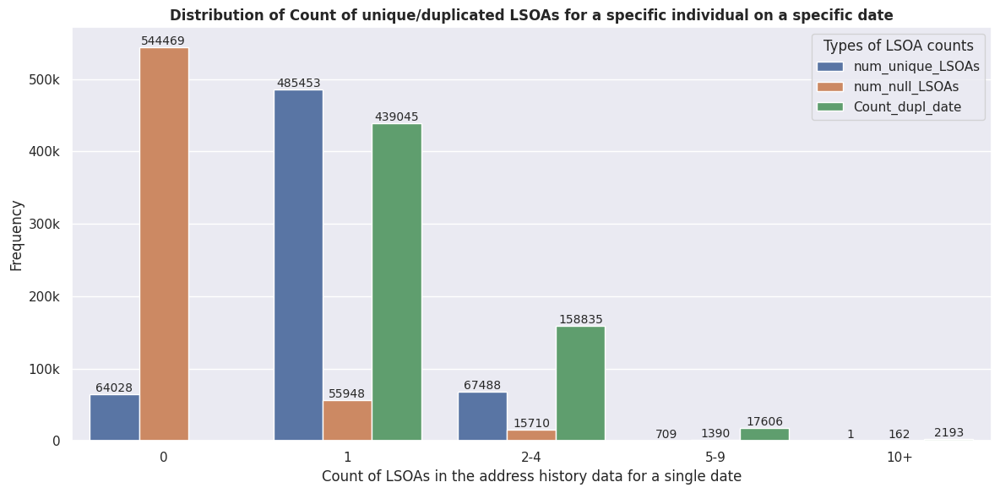

In [123]:
from matplotlib.ticker import FuncFormatter

combined_count_person_lsoa_melted = combined_count_person_lsoa.melt(
    id_vars=['person_id_hashed', 'DateTo'],
    value_vars=['num_unique_LSOAs', 'num_null_LSOAs', 'Count_dupl_date'],
    var_name='Count_Type',
    value_name='Value'
)

bins = [-1, 0, 1, 4, 9, float('inf')] 
labels = ['0', '1', '2-4', '5-9', '10+']

combined_count_person_lsoa_melted['Value_cat'] = pd.cut(combined_count_person_lsoa_melted['Value'], bins=bins, labels=labels, right=True)

plt.figure(figsize=(12, 6))
ax = sns.countplot(
    data=combined_count_person_lsoa_melted,
    x='Value_cat',
    hue='Count_Type',
    order=labels
)

for container in ax.containers:
    ax.bar_label(container, label_type='edge', fontsize=10)

ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{int(x/1000)}k' if x >= 1000 else str(int(x))))
plt.title('Distribution of Count of unique/duplicated LSOAs for a specific individual on a specific date',fontweight='bold')
plt.xlabel('Count of LSOAs in the address history data for a single date')
plt.ylabel('Frequency')
plt.legend(title='Types of LSOA counts')
plt.tight_layout()
plt.show()

In [64]:
lsoa_df_sorted.groupby(['person_id_hashed','DateTo'])['SOA'].unique()

person_id_hashed                                                  DateTo    
0000E56BF6A95C62902FFD153B93FDB623A64E1E4D6CBB228EF8850A20B1F5CF  2017-11-30    [E01010758]
000271DE16992FF0D5D4880BA40A407FC6D7003F8C224B17EBAEFB5D0DF73D89  2019-09-09    [E01010843]
                                                                  2019-12-05    [E01010843]
00033EE6766805019994E5E629073808FCEDB88937DFC60A3F64B8167DC311D9  2015-01-09    [E01010789]
0003E6115323C6B432341C1B3A8BB886B510C5FC879C74FCB72617BA5FC349DC  2014-06-20    [E01010614]
                                                                                   ...     
FFFF82B02316928365A483197B8248451DD0CE55FE73789BD33A2DE7C7F78ECC  2021-06-03    [E01011542]
                                                                  2022-07-26    [E01011542]
FFFF9795608A02253A29243FB53AC2EE67FDEE7AD42064099300EE69B2DBF9CB  2016-03-10    [E01010779]
                                                                  2016-12-13    [E01010653]
   